In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_csv("uber.csv")

print(df.shape)
df.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [2]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

dt = pd.to_datetime(df['pickup_datetime'], errors='coerce')
df = df[dt.notna()].copy()
dt = pd.to_datetime(df['pickup_datetime'])

df['hour'] = dt.dt.hour
df['day'] = dt.dt.day
df['month'] = dt.dt.month
df['weekday'] = dt.dt.weekday

df = df[
    df['pickup_latitude'].between(-90, 90) &
    df['dropoff_latitude'].between(-90, 90) &
    df['pickup_longitude'].between(-180, 180) &
    df['dropoff_longitude'].between(-180, 180)
].copy()

lat1, lon1, lat2, lon2 = np.radians([
    df['pickup_latitude'], df['pickup_longitude'],
    df['dropoff_latitude'], df['dropoff_longitude']
])

df['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(
    np.sin((lat2-lat1)/2)**2 +
    np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
))

df.drop(columns=['key', 'pickup_datetime', 'Unnamed: 0',
                 'pickup_latitude', 'pickup_longitude',
                 'dropoff_latitude', 'dropoff_longitude'],
        inplace=True, errors='ignore')

df = df[
    (df['fare_amount'].between(0.01, 100)) &
    (df['distance_km'].between(0.01, 100)) &
    (df['passenger_count'].between(1, 6))
]

df.head()

,fare_amount,passenger_count,hour,day,month,weekday,distance_km
0,7.5,1,19,7,5,3,1.683323
1,7.7,1,20,17,7,4,2.457590
2,12.9,1,21,24,8,0,5.036377
3,5.3,3,8,26,6,4,1.661683
4,16.0,5,17,28,8,3,4.475450


fare_amount Outliers: 16331
distance_km Outliers: 15985


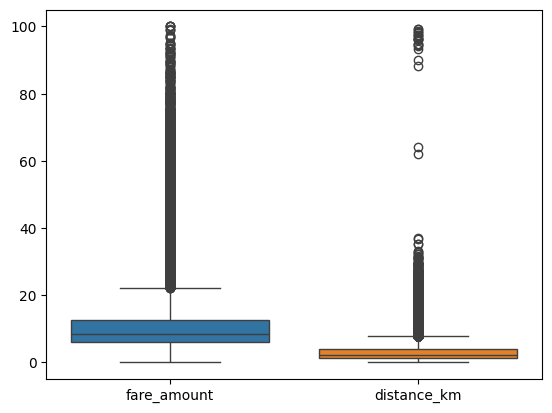

In [3]:
for col in ['fare_amount', 'distance_km']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    count = ((df[col] < q1 - 1.5*iqr) |
             (df[col] > q3 + 1.5*iqr)).sum()
    print(col, "Outliers:", count)

sns.boxplot(data=df[['fare_amount', 'distance_km']])
plt.show()

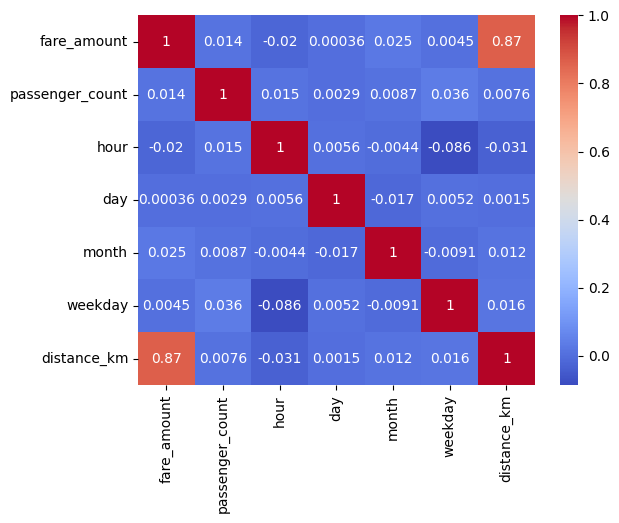

In [4]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

In [6]:
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

In [7]:
rf = RandomForestRegressor(
    n_estimators=50, max_depth=15,
    random_state=42, n_jobs=-1
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [9]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [r2_score(y_test, lr_pred),
                 r2_score(y_test, rf_pred)],
    'MSE': [mean_squared_error(y_test, lr_pred),
            mean_squared_error(y_test, rf_pred)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, lr_pred)),
             np.sqrt(mean_squared_error(y_test, rf_pred))],
    'MAE': [mean_absolute_error(y_test, lr_pred),
            mean_absolute_error(y_test, rf_pred)]
})

display(results)

,Model,R2 Score,MSE,RMSE,MAE
0,Linear Regression,0.69242,26.282694,5.126665,2.356936
1,Random Forest,0.79505,17.512975,4.184851,2.254212
